<a href="https://colab.research.google.com/github/160423737030-lab/Codveda-Machine-Learning-Internship/blob/main/level2_task1_logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Shape: (569, 31)
Target Class Distribution:
 target
1    357
0    212
Name: count, dtype: int64
Missing Values: 0

Top 10 Most Influential Features (Coefficients & Odds Ratios):
             Feature  Coefficient (log-odds)  Odds Ratio (exp(coef))
       worst texture               -1.255088                0.285051
        radius error               -1.082965                0.338590
worst concave points               -0.953686                0.385318
          worst area               -0.947756                0.387610
        worst radius               -0.947616                0.387664
      worst symmetry               -0.939181                0.390948
          area error               -0.929104                0.394907
     worst concavity               -0.823151                0.439046
     worst perimeter               -0.763220                0.466163
    worst smoothness               -0.746625                0.473964

Accuracy:  0.9825
Precision: 0.9861
Recall:    0.9861


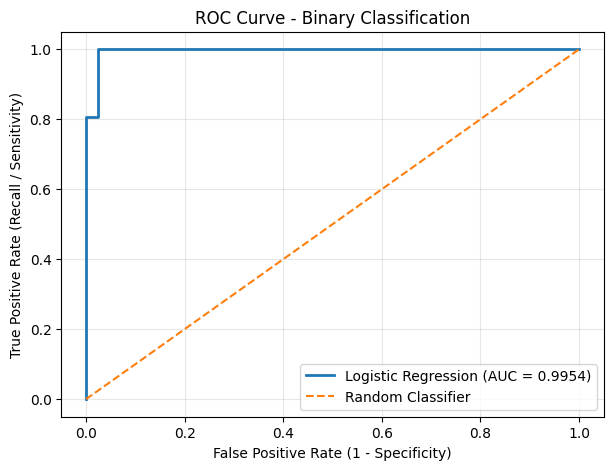

In [1]:
# ==========================================
# Codveda Technologies - Machine Learning Internship
# Level 2 (Intermediate) - Task 1: Logistic Regression for Binary Classification
# Intern: MD JUNAID KHAN
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    roc_curve,
    roc_auc_score
)

# 1. Load Binary Classification Dataset (Breast Cancer: 0 = malignant, 1 = benign)
data = load_breast_cancer(as_frame=True)
df = data.frame
X = data.data
y = data.target

print("Dataset Shape:", df.shape)
print("Target Class Distribution:\n", y.value_counts())
print("Missing Values:", df.isnull().sum().sum())

# 2. Train-Test Split (80% Train, 20% Test, stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Feature Scaling (Standardize features for Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Train Logistic Regression Model
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

# 5. Interpret Model Coefficients & Odds Ratios
# Note: Odds Ratio = exp(coefficient) for a 1-std-dev increase in the feature
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient (log-odds)': model.coef_[0],
    'Odds Ratio (exp(coef))': np.exp(model.coef_[0])
}).sort_values(by='Coefficient (log-odds)', key=abs, ascending=False)

print("\nTop 10 Most Influential Features (Coefficients & Odds Ratios):")
print(coef_df.head(10).to_string(index=False))

# 6. Predictions & Evaluation Metrics (Accuracy, Precision, Recall)
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
auc_score = roc_auc_score(y_test, y_prob)

print(f"\nAccuracy:  {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"ROC-AUC:   {auc_score:.4f}")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

# 7. Plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, linewidth=2, label=f'Logistic Regression (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')
plt.title('ROC Curve - Binary Classification')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall / Sensitivity)')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()